# Day 22 Capstone: Energy-Demand Forecasting with LSTM + Attention

Build an end-to-end 24-hour-ahead forecaster on a self-generated hourly energy-demand series (trend + daily cycle + weekly cycle + weekend dip + noise). All data is generated in code, with nothing downloaded.

Steps: 1 windowing, 2 chronological split and train-only normalisation, 3 seasonal-naive baseline, 4 LSTM, 5 LSTM + attention, 6 evaluation, 7 plot narration and teacher forcing, 8 written analysis.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

RNG = 42
np.random.seed(RNG)
tf.random.set_seed(RNG)

# ---- Generate 2 years of hourly demand, fully offline ----
N = 24 * 7 * 104            # ~104 weeks of hourly readings
t = np.arange(N)

trend = 0.0015 * t                                   # slow upward drift
daily = 8.0 * np.sin(2*np.pi * t / 24 - 1.0)         # 24h cycle, peak in afternoon
weekly = 4.0 * np.sin(2*np.pi * t / (24*7))          # 7-day cycle (weekday/weekend)
weekend = -3.0 * (((t // 24) % 7) >= 5)              # lower demand Sat/Sun
noise = np.random.normal(0, 1.2, N)                  # irreducible error
demand = 50.0 + trend + daily + weekly + weekend + noise
demand = demand.astype("float32")

print("series length:", demand.shape, " mean:", round(float(demand.mean()),2),
      " min:", round(float(demand.min()),2), " max:", round(float(demand.max()),2))

series length: (17472,)  mean: 62.25  min: 33.44  max: 89.14


## Step 1: Frame the problem with sliding windows (168 h look-back, 24 h horizon)

In [2]:
LOOKBACK = 168     # one week of hourly context
HORIZON = 24       # forecast the next 24 hours

def make_windows(series, lookback, horizon):
    X, y = [], []
    for i in range(len(series) - lookback - horizon + 1):
        X.append(series[i : i + lookback])
        y.append(series[i + lookback : i + lookback + horizon])
    return np.array(X, dtype="float32"), np.array(y, dtype="float32")

X_all, y_all = make_windows(demand, LOOKBACK, HORIZON)
print("X_all:", X_all.shape, " y_all:", y_all.shape)

X_all: (17281, 168)  y_all: (17281, 24)


## Step 2: Chronological split (70/15/15) and train-only normalisation

In [3]:
n = len(X_all)
i_tr = int(n * 0.70)
i_va = int(n * 0.85)

X_tr_raw, y_tr_raw = X_all[:i_tr], y_all[:i_tr]
X_va_raw, y_va_raw = X_all[i_tr:i_va], y_all[i_tr:i_va]
X_te_raw, y_te_raw = X_all[i_va:], y_all[i_va:]

mu = X_tr_raw.mean()        # fit on TRAIN inputs only
sigma = X_tr_raw.std()

def norm(a): return (a - mu) / sigma
def denorm(a): return a * sigma + mu

X_tr, y_tr = norm(X_tr_raw), norm(y_tr_raw)
X_va, y_va = norm(X_va_raw), norm(y_va_raw)
X_te, y_te = norm(X_te_raw), norm(y_te_raw)

# add the feature-channel axis Keras RNNs expect: (samples, timesteps, features)
X_tr = X_tr[..., None]; X_va = X_va[..., None]; X_te = X_te[..., None]
print("train:", X_tr.shape, " val:", X_va.shape, " test:", X_te.shape)
print("norm stats mu:", round(float(mu),3), " sigma:", round(float(sigma),3))

train: (12096, 168, 1)  val: (2592, 168, 1)  test: (2593, 168, 1)
norm stats mu: 58.335  sigma: 8.689


## Step 3: Seasonal-naive baseline (the yardstick)

In [4]:
def mae(a, b):  return float(np.mean(np.abs(a - b)))
def rmse(a, b): return float(np.sqrt(np.mean((a - b) ** 2)))
def mape(a, b): return float(np.mean(np.abs((a - b) / a)) * 100)

# seasonal-naive: predict horizon = last 24 real hours of each look-back window
baseline_pred = X_te_raw[:, -HORIZON:]     # (test, 24) in ORIGINAL units
y_te_true = y_te_raw                       # (test, 24) in ORIGINAL units

b_mae = mae(y_te_true, baseline_pred)
b_rmse = rmse(y_te_true, baseline_pred)
b_mape = mape(y_te_true, baseline_pred)
print(f"SEASONAL-NAIVE  MAE={b_mae:.3f}  RMSE={b_rmse:.3f}  MAPE={b_mape:.2f}%")

SEASONAL-NAIVE  MAE=3.232  RMSE=3.869  MAPE=4.45%


## Step 4: LSTM direct forecaster

In [5]:
def build_lstm():
    inp = keras.Input(shape=(LOOKBACK, 1))
    x = layers.LSTM(48)(inp)                    # encoder -> final hidden state
    x = layers.Dropout(0.1)(x)
    out = layers.Dense(HORIZON)(x)              # emit 24 steps directly
    m = keras.Model(inp, out, name="lstm_direct")
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse", metrics=["mae"])
    return m

lstm = build_lstm()
es = keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)
hist = lstm.fit(X_tr, y_tr, validation_data=(X_va, y_va),
                epochs=15, batch_size=128, callbacks=[es], verbose=2)
print("epochs run:", len(hist.history["loss"]),
      " best val_mae(norm):", round(min(hist.history["val_mae"]), 4))

Epoch 1/15


95/95 - 3s - 28ms/step - loss: 0.5924 - mae: 0.6179 - val_loss: 0.3401 - val_mae: 0.4679


Epoch 2/15


95/95 - 3s - 31ms/step - loss: 0.1205 - mae: 0.2721 - val_loss: 0.1487 - val_mae: 0.3025


Epoch 3/15


95/95 - 4s - 41ms/step - loss: 0.0798 - mae: 0.2218 - val_loss: 0.1113 - val_mae: 0.2583


... (7 outputs left out)

95/95 - 4s - 37ms/step - loss: 0.0502 - mae: 0.1766 - val_loss: 0.1014 - val_mae: 0.2461


Epoch 8/15


95/95 - 4s - 42ms/step - loss: 0.0475 - mae: 0.1720 - val_loss: 0.0994 - val_mae: 0.2395


epochs run: 8  best val_mae(norm): 0.2343


## Step 5: Add attention over the encoder states

In [6]:
def build_lstm_attention():
    inp = keras.Input(shape=(LOOKBACK, 1))
    enc = layers.LSTM(48, return_sequences=True)(inp)     # (batch, 168, 48) all states
    # attention: query = the full encoder sequence attending to itself
    ctx = layers.Attention()([enc, enc])                  # weighted context over time
    ctx = layers.LayerNormalization()(ctx + enc)          # residual + norm
    pooled = layers.GlobalAveragePooling1D()(ctx)         # summarize the attended states
    x = layers.Dropout(0.1)(pooled)
    out = layers.Dense(HORIZON)(x)
    m = keras.Model(inp, out, name="lstm_attention")
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse", metrics=["mae"])
    return m

lstm_attn = build_lstm_attention()
es2 = keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)
hist2 = lstm_attn.fit(X_tr, y_tr, validation_data=(X_va, y_va),
                      epochs=15, batch_size=128, callbacks=[es2], verbose=2)
print("epochs run:", len(hist2.history["loss"]),
      " best val_mae(norm):", round(min(hist2.history["val_mae"]), 4))
print(lstm_attn.count_params(), "params vs", lstm.count_params(), "for plain LSTM")

Epoch 1/15


95/95 - 8s - 86ms/step - loss: 0.8142 - mae: 0.7334 - val_loss: 0.8288 - val_mae: 0.7453


Epoch 2/15


95/95 - 8s - 81ms/step - loss: 0.6718 - mae: 0.6785 - val_loss: 0.6804 - val_mae: 0.6796


Epoch 3/15


95/95 - 8s - 81ms/step - loss: 0.6149 - mae: 0.6510 - val_loss: 0.6289 - val_mae: 0.6545


... (21 outputs left out)

95/95 - 10s - 109ms/step - loss: 0.0472 - mae: 0.1710 - val_loss: 0.0741 - val_mae: 0.2082


Epoch 15/15


95/95 - 10s - 106ms/step - loss: 0.0459 - mae: 0.1686 - val_loss: 0.1040 - val_mae: 0.2427


epochs run: 15  best val_mae(norm): 0.2082
10872 params vs 10776 for plain LSTM


## Step 6: Evaluate all three models in real demand units

In [7]:
def score_model(model, name):
    pred = denorm(model.predict(X_te, verbose=0))     # back to original units
    return name, mae(y_te_true, pred), rmse(y_te_true, pred), mape(y_te_true, pred)

rows = [
    ("seasonal-naive", b_mae, b_rmse, b_mape),
    score_model(lstm, "lstm"),
    score_model(lstm_attn, "lstm+attention"),
]

print(f"{'model':16s} {'MAE':>8s} {'RMSE':>8s} {'MAPE%':>8s}")
for nm, a, r, p in rows:
    print(f"{nm:16s} {a:8.3f} {r:8.3f} {p:8.2f}")

best = min(rows, key=lambda z: z[1])
print("\nlowest MAE:", best[0])

model                 MAE     RMSE    MAPE%
seasonal-naive      3.232    3.869     4.45
lstm                3.218    4.029     4.30
lstm+attention      3.376    4.643     4.62

lowest MAE: lstm


## Step 7: The forecast plot, in words, and teacher forcing vs autoregressive inference

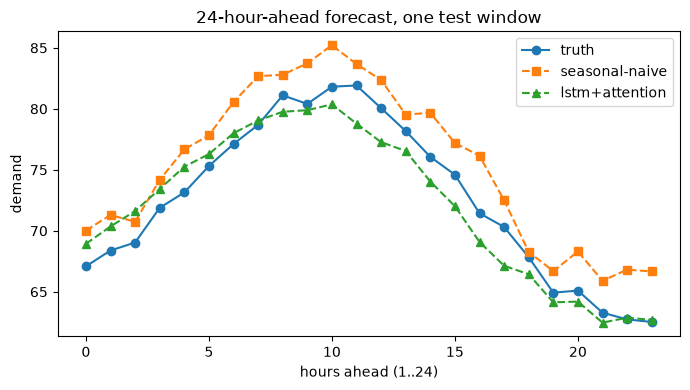

truth[:6] : [67.09 68.39 69.04 71.89 73.15 75.31]
naive[:6] : [70.02 71.3  70.74 74.18 76.67 77.83]
net  [:6] : [68.93 70.36 71.62 73.43 75.26 76.29]


In [8]:
k = 0                                   # first test window
truth = y_te_true[k]
naive = baseline_pred[k]
net = denorm(lstm_attn.predict(X_te[k:k+1], verbose=0))[0]

plt.figure(figsize=(7,4))
plt.plot(truth, "o-", label="truth")
plt.plot(naive, "s--", label="seasonal-naive")
plt.plot(net, "^--", label="lstm+attention")
plt.xlabel("hours ahead (1..24)"); plt.ylabel("demand")
plt.title("24-hour-ahead forecast, one test window"); plt.legend(); plt.tight_layout(); plt.show()

print("truth[:6] :", np.round(truth[:6], 2))
print("naive[:6] :", np.round(naive[:6], 2))
print("net  [:6] :", np.round(net[:6], 2))

In [9]:
# numbers behind the plot narration: average error per forecast hour for each method
net_all = denorm(lstm_attn.predict(X_te, verbose=0))
err_naive = np.abs(y_te_true - baseline_pred).mean(axis=0)
err_net = np.abs(y_te_true - net_all).mean(axis=0)
print("window 0 abs error  naive: %.3f   lstm+attention: %.3f" % (np.abs(truth-naive).mean(), np.abs(truth-net).mean()))
print("mean abs error by hour ahead (1, 6, 12, 18, 24)")
print("  naive:", np.round(err_naive[[0, 5, 11, 17, 23]], 2))
print("  net  :", np.round(err_net[[0, 5, 11, 17, 23]], 2))

window 0 abs error  naive: 2.771   lstm+attention: 1.563
mean abs error by hour ahead (1, 6, 12, 18, 24)
  naive: [3.24 3.23 3.23 3.23 3.23]
  net  : [4.68 2.94 2.88 3.13 3.96]


**What the plot shows.** For the first test window, the LSTM+attention line follows the truth's afternoon climb more closely than the seasonal-naive line, which sits about 2 to 3 units too high across the first six hours (mean abs error 1.56 vs 2.77 for this window). That is one window only: averaged over the whole test set the network is *not* better. Its error by forecast hour is about 4.7 at hour 1, 2.9 at hours 6 and 12, and 4.0 at hour 24, while the naive error is flat at about 3.2.

**Teacher forcing vs autoregressive.** Our models are *direct* multi-output forecasters: one pass emits all 24 hours, so there is no decoder loop and no teacher forcing at inference. A seq2seq decoder trained with teacher forcing sees the true previous value during training but its own previous prediction at inference. That mismatch (exposure bias) lets a small early error feed into later steps and compound.

## Step 8: Analysis

In [10]:
# Sanity-print the numbers the analysis must cite, so the write-up stays honest.
print("BASELINE MAE=%.3f RMSE=%.3f MAPE=%.2f%%" % (b_mae, b_rmse, b_mape))
for nm, a, r, p in rows[1:]:
    print("%-13s MAE=%.3f RMSE=%.3f MAPE=%.2f%% (dMAE vs baseline=%+.3f)"
          % (nm, a, r, p, a - b_mae))

BASELINE MAE=3.232 RMSE=3.869 MAPE=4.45%
lstm          MAE=3.218 RMSE=4.029 MAPE=4.30% (dMAE vs baseline=-0.014)
lstm+attention MAE=3.376 RMSE=4.643 MAPE=4.62% (dMAE vs baseline=+0.144)


### Analysis

**Learning vs baseline.** Barely, and not for attention. Seasonal-naive scored MAE 3.232, RMSE 3.869, MAPE 4.45%. The plain LSTM scored MAE 3.218 (-0.014), RMSE 4.029 (+0.160, worse) and MAPE 4.30% (-0.15). That is a tie, well inside run-to-run noise. The daily cycle is nearly deterministic, so yesterday's 24 hours are already a strong forecast.

**Did attention earn its parameters?** No. LSTM+attention (+96 parameters) got MAE 3.376, RMSE 4.643, MAPE 4.62%, worse than both, even though it had the best *validation* MAE (0.208 vs 0.234 normalised). The likely reason, which I did not test, is that validation and test sit at different points of the rising trend. Attention would matter more for longer horizons, irregular seasonality or exogenous drivers.

**Leakage and honesty.** The split was chronological (70/15/15) and mean and std came from train inputs only. The test set was scored once, with no tuning on it.

**Teacher forcing.** Both networks are direct forecasters, so inference uses no teacher forcing. An autoregressive decoder risks exposure bias: errors compound step by step.

**Next step.** Add hour-of-day and day-of-week features and de-trend the series, then repeat with several seeds.